# A Rietveld refinement of your own data

A template: change the cells marked ✏️ and run the notebook top to bottom.
As shipped it runs on the fluorapatite example from notebooks 01 and 02, so you can see every output before you change anything.

**In Colab**, upload your files with the folder icon in the left sidebar.
Right-click a file and choose *Copy path* to get its path, which starts `/content/`.
Files there are deleted when the runtime stops, so download what the last cell writes.

In [ ]:
%pip install rietx

## Your files and instrument ✏️

In [1]:
from pathlib import Path

import numpy as np

import rietx as rx
from rietx.examples import examples_dir

PATTERN = examples_dir() / "FAP.XRA"            # ✏️ your pattern
CIFS = [examples_dir() / "fluorapatite.cif"]    # ✏️ one CIF per crystalline phase
RADIATION = "CuKa"                              # ✏️ the anode: "CuKa", "CoKa", "MoKa", ...
TWO_THETA_LIMITS = (15, 130)                    # ✏️ the range to fit, in degrees 2θ; None fits all of it
OUTPUT = Path("rietx_output")                   # where the last cell writes

`rx.read_pattern` reads the format from the file.
`rx.capabilities().reader_formats` lists every format it opens.

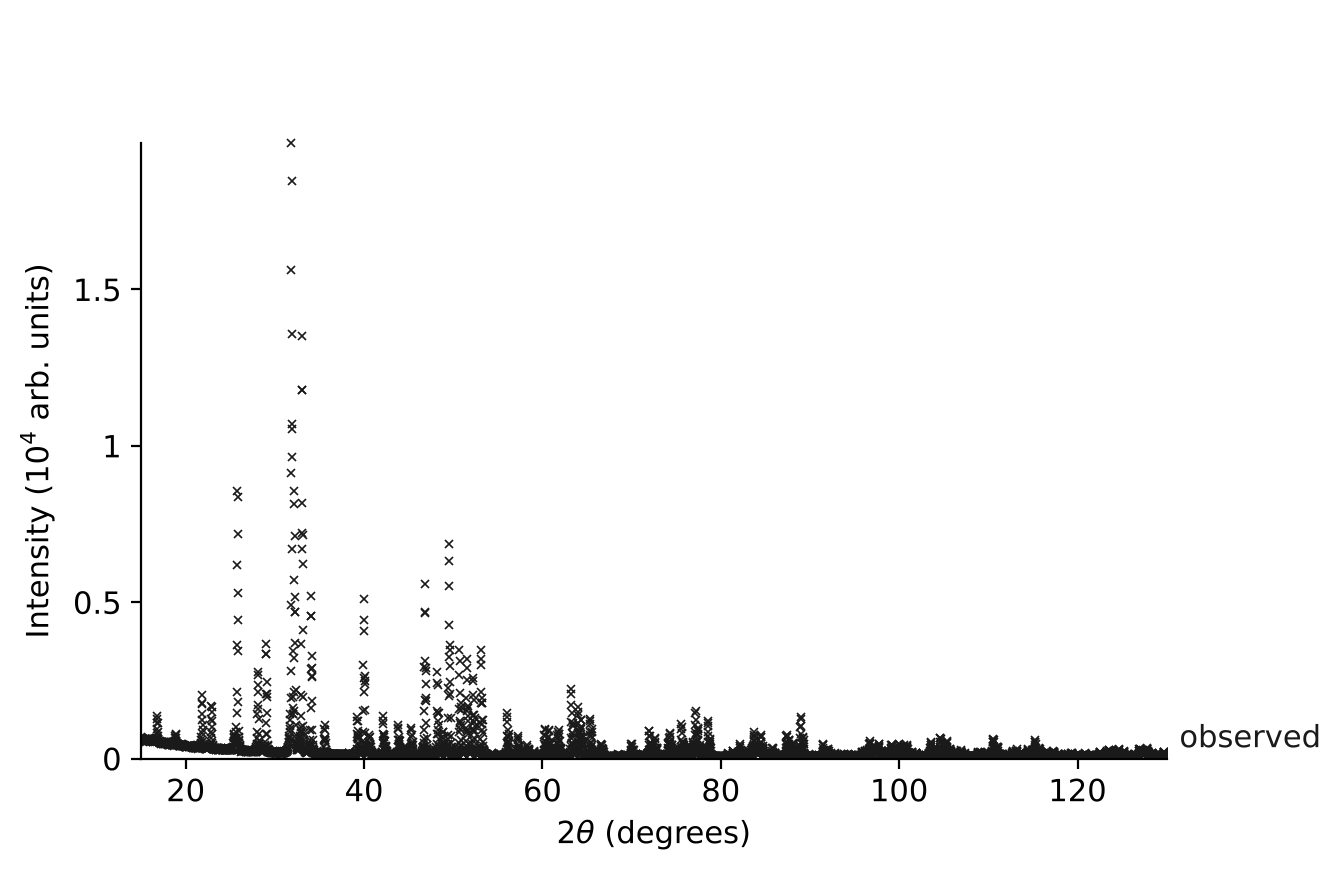

In [2]:
data = rx.read_pattern(PATTERN)
data.plot()

Check the data before modelling it.
Fewer than about five steps across a peak's width limits what the peak shape can tell you.
A contaminating line, such as Kβ or tungsten Lα from an old tube, needs its range excluded or a line added to the source.

In [3]:
diag = rx.diagnose(data)
print(f"steps across a peak's FWHM: {diag.steps_per_fwhm:.1f}")
print(f"signal over background:     {diag.signal_to_background:.0f}")
print(f"contaminating lines:        {diag.contamination or 'none'}")
print(f"dead channels:              {diag.dead_channels or 'none'}")

steps across a peak's FWHM: 4.6
signal over background:     146
contaminating lines:        none
dead channels:              none


## The model, checked before fitting

For a capillary or a synchrotron pattern, replace the instrument with `rx.Instrument.debye_scherrer(wavelength=...)`, the wavelength in Å.

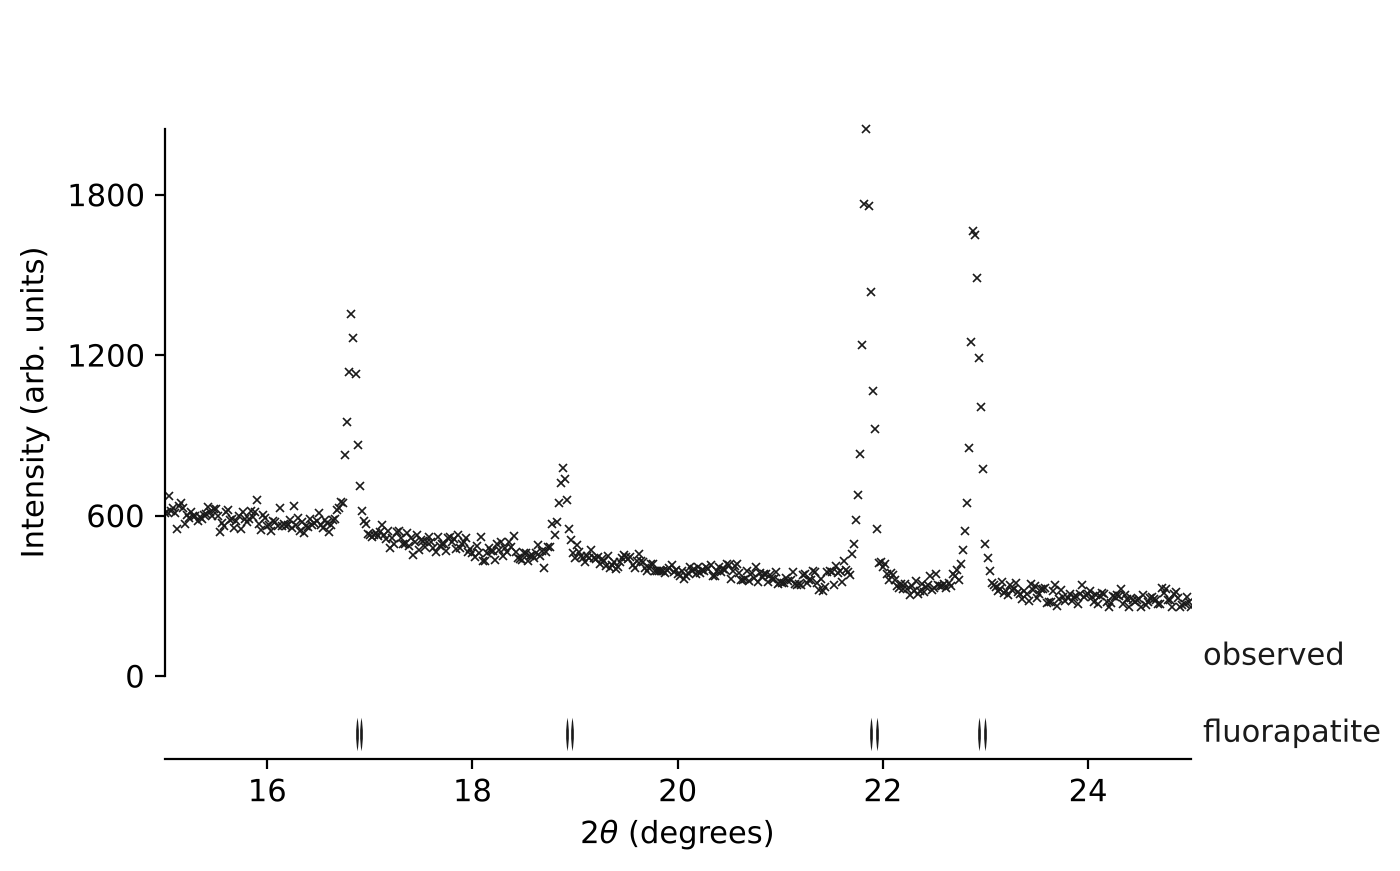

In [4]:
phases = [phase for cif in CIFS for phase in rx.Structure.from_cif(cif).phases]
structure = rx.Structure(phases=phases)

instrument = rx.Instrument.bragg_brentano(radiation=RADIATION)
instrument.background = rx.BackgroundChebyshev.with_terms(6)
instrument.background.coefficients[0].value = float(np.percentile(data.intensity, 5))

ref = rx.Refinement(structure, instrument)
low = TWO_THETA_LIMITS[0] if TWO_THETA_LIMITS else min(data.two_theta)
data.plot(model=ref, two_theta_range=(low, low + 10))  # ✏️ any 10° with strong peaks

Every observed peak in the window should have a tick under it.
Ticks offset by the same amount everywhere point to the cell or the zero shift.
Peaks with no tick point to a phase you have not given a CIF for.

## Le Bail: does the cell index the pattern?

Le Bail fits the cell and the peak shapes with free intensities.
If it cannot fit the pattern, a Rietveld fit will not either.
It runs on a copy of the model, so the Rietveld fit below starts from the CIF.

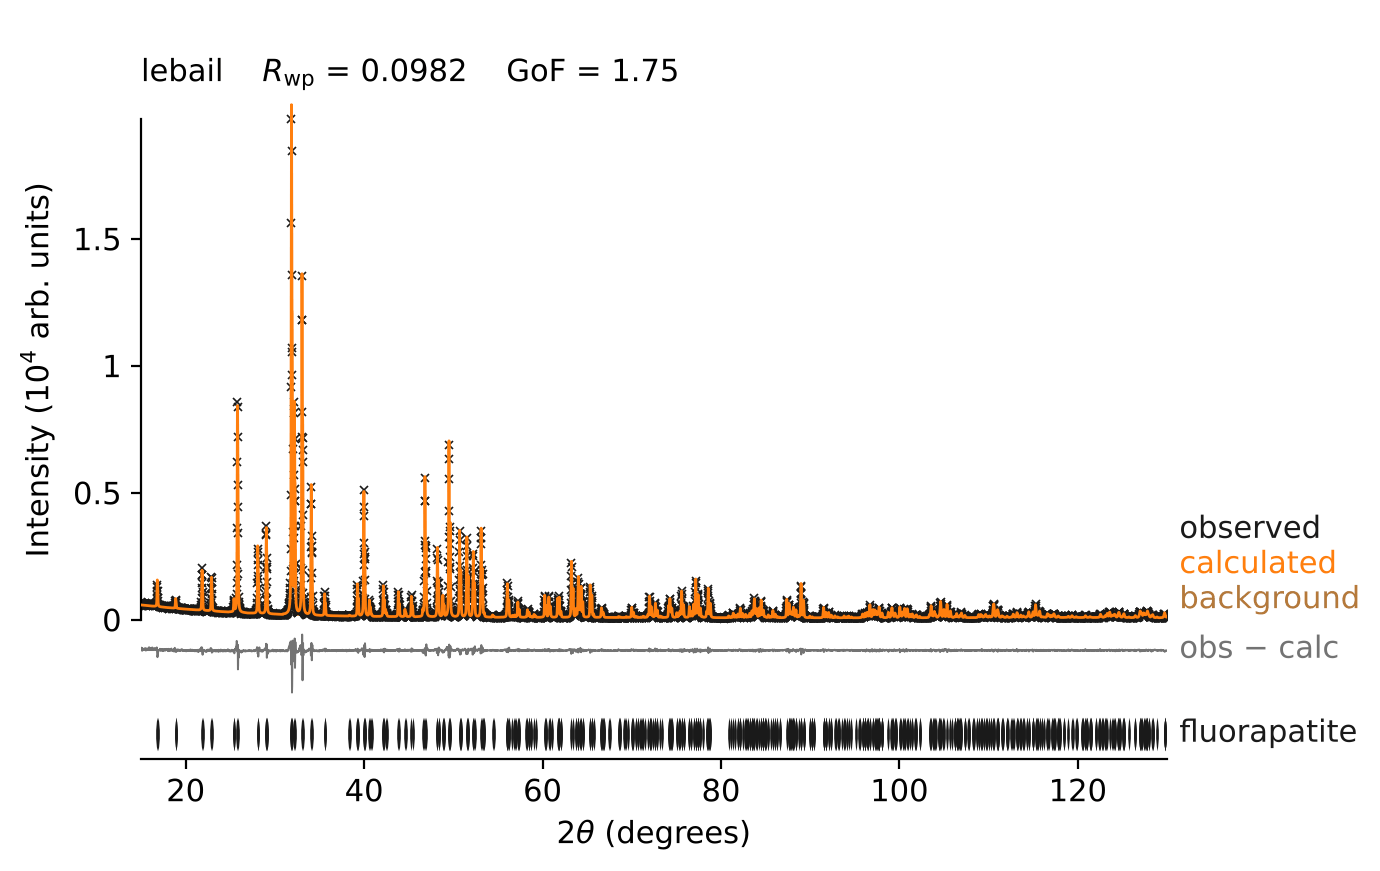

In [5]:
lebail = rx.Refinement(structure, instrument).fit(
    data, mode="lebail", plan="profile_only", two_theta_limits=TWO_THETA_LIMITS)
lebail.plot()

A flat difference curve here means the cell and the peak shapes are right.
Keep its Rwp: a Rietveld Rwp well above it points at the structure model rather than the cell or the peaks.
It is not a floor: this Le Bail plan frees fewer instrument terms than the Rietveld one, so a Rietveld Rwp a little below it is normal.

## Rietveld

`mccusker_structural` frees background and scale first, then the cell and peak widths, then the atoms.
`rx.PLAN_INFO` lists the other plans and what each is for.

Le Bail Rwp 0.0982, Rietveld Rwp 0.0936


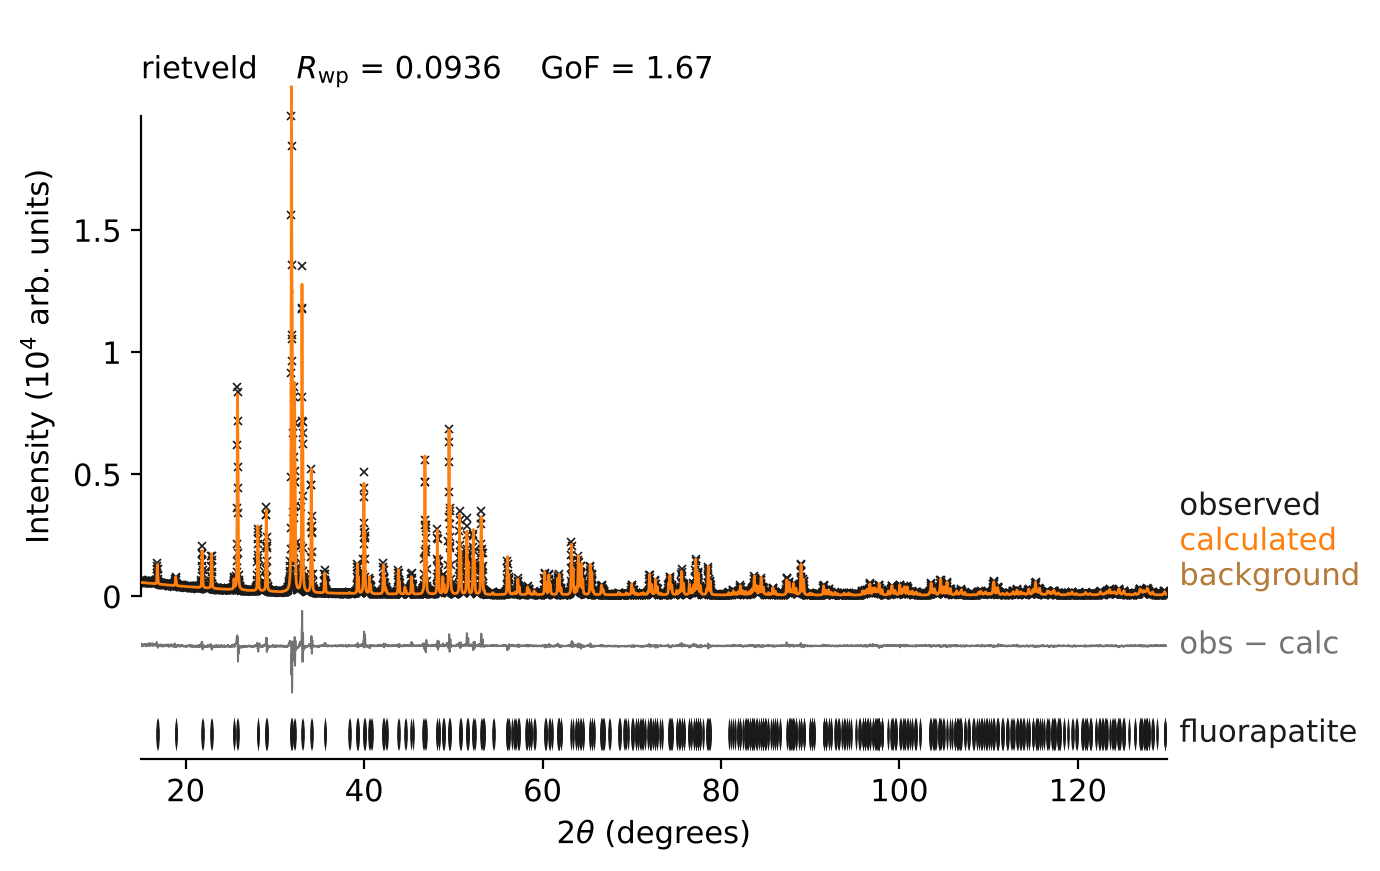

In [6]:
result = ref.fit(data, plan="mccusker_structural", two_theta_limits=TWO_THETA_LIMITS)
print(f"Le Bail Rwp {lebail.statistics.rwp:.4f}, Rietveld Rwp {result.statistics.rwp:.4f}")
result.plot()

## What the fit says about itself

Read every diagnostic before quoting a number.
`deliverable` picks the rows that decide whether the fit is done for one purpose: `"structure"`, `"qpa"`, `"phase_id"` or `"series"`.

In [7]:
print(ref.summary(deliverable="structure"))

Refinement.summary: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage zero: converged (48 evals, ftol=1e-06)
  stage cell: converged (25 evals, ftol=1e-06)
  stage profile_w: converged (14 evals, ftol=1e-06)
  stage profile: converged (18 evals, ftol=1e-06)
  stage extra_components: converged (7 evals, ftol=1e-06)
  stage coordinates: converged (6 evals, ftol=1e-06)
  stage biso: converged (6 evals, ftol=1e-06)
  stage preferred_orientation: converged (4 evals, ftol=1e-06)
  stage extinction: converged (3 evals, ftol=1e-06)
  stage roughness: converged (1 evals, ftol=solver default)
  diagnostics: 4 unresolved
    WARNING SITE_SNAPPED_TO_SPECIAL_POSITION: 1 site(s) in phase 'fluorapatite' sit within 0.0001 of a special position of 'P 63/m' without being on it, and were expanded at it: Ca1 (3.3e-11 → multiplicity 4). Largest shift 3.33e-11 in fractional coordinates — the stored coordinates are unchanged and the fit is unaffected, but the multiplicity is the

## The refined structure

The default view is oblique.
`view` takes `"a"`, `"b"`, `"c"`, a direction `[u, v, w]`, a plane normal `{"hkl": (h, k, l)}`, or `"auto"`, which picks the low-index direction that hides the fewest atoms.
A view down a symmetry axis is often the one a reader recognises.
`turn="-15x"` tips the view, and `atom_labels=True` names the sites.

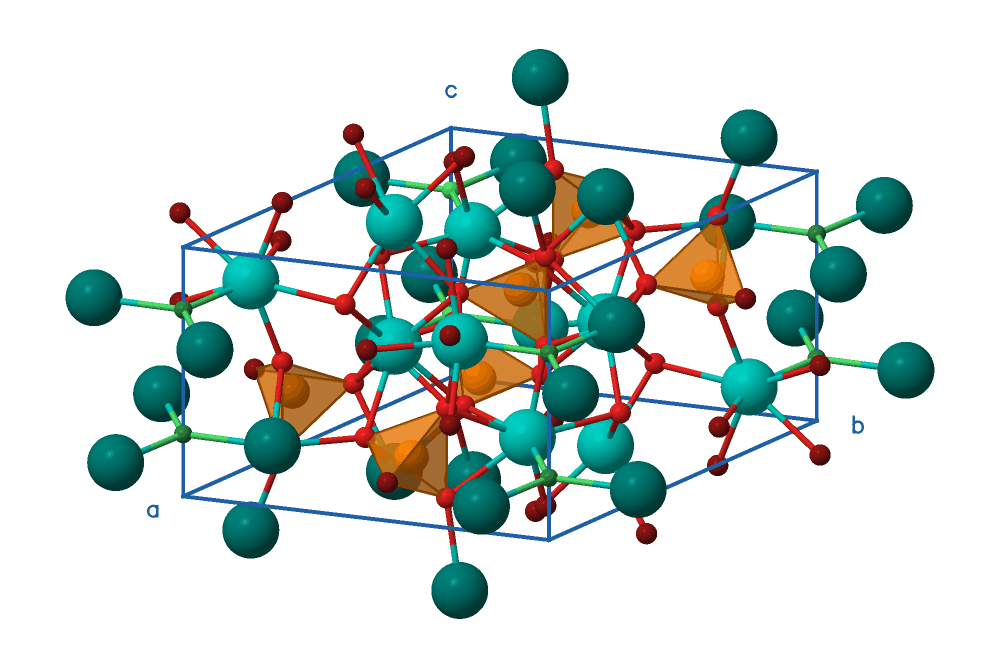

In [8]:
rx.viz.render_structure(ref.structure)  # ✏️ view=, turn=, phase=1 for a second phase

## Save the results

The CIF carries the refined structure with its esds, the R factors and the pattern.
The project directory starts from the refined model with these settings, and `rietx gui` opens it.
It does not hold this fit's stages: a fit run through `rx.Project` would record them.

In [9]:
OUTPUT.mkdir(exist_ok=True)
rx.write_refinement_cif(result, ref.fitted_structure, ref.instrument,
                        OUTPUT / "refined.cif", pattern=data)
result.plot(path=OUTPUT / "fit.png")
rex = OUTPUT / "refinement.rex"
if rex.exists():
    print(f"{rex} exists and was kept: delete or rename it to save this fit as a project")
else:
    rx.Project.create(rex, pattern=PATTERN, structure=ref.structure, instrument=ref.instrument,
                      plan="mccusker_structural", two_theta_limits=TWO_THETA_LIMITS).save()
print(sorted(item.name for item in OUTPUT.iterdir()))

['fit.png', 'refined.cif', 'refinement.rex']
